# 08. NGHIỆM THU ĐỘC LẬP TRÊN TẬP KIỂM THỬ CUỐI CÙNG (FINAL TEST EVALUATION)
## ĐÁNH GIÁ MÔ HÌNH CHAMPION VÀ ĐỐI SÁNH HIỆU NĂNG NGOẠI MẪU (OUT-OF-SAMPLE)

---

* **Học phần:** Khai phá Dữ liệu (Data Mining) — Học viện Công nghệ Bưu chính Viễn thông (PTIT)
* **Đề tài số 13:** Credit Card Fraud Detection (Unsupervised Anomaly Detection)
* **Giai đoạn thực hiện:** Phase 8 — Frozen Final Holdout Evaluation & Independent Benchmark
* **Sinh viên thực hiện:**
  * Nguyễn Văn Hiển Vinh (B23DCVT461) — Trưởng nhóm / Data & Preprocessing Lead
  * Nguyễn Minh Hoàng (B23DCVT173) — Kỹ sư Mô hình hóa / Modeling & Evaluation Lead

> **TUYÊN BỐ CHÍNH SÁCH BẢO VỆ TẬP TEST (STRICT FINAL TEST POLICY):**
> 1. **Mở niêm phong 01 lần duy nhất:** Tập Test (42,722 giao dịch, 74 Fraud) được giữ nguyên vẹn từ Phase 2 và chỉ được mở ra ở giai đoạn này để nghiệm thu độc lập.
> 2. **Tuyệt đối KHÔNG tái huấn luyện (No Retraining):** Cả 3 mô hình đều được nạp từ checkpoint đã đóng băng tại Phase 3–5.
> 3. **Tuyệt đối KHÔNG tinh chỉnh ngưỡng (No Threshold Tuning on Test):** Ngưỡng quyết định $\tau^*$ được cố định chính xác bit-for-bit từ kết quả tối ưu hóa trên tập Validation ở Phase 6.
> 4. **Bảo toàn Champion:** Mô hình Champion (Local Outlier Factor) được giữ nguyên, kết quả trên Test chỉ nhằm đo lường khả năng tổng quát hóa thực tế.


In [1]:
import json
import sys
import time
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score

from src.config import COST_FP, DEFAULT_COST_FN, FIGURES_DIR, PROCESSED_DATA_DIR, RANDOM_STATE
from src.metrics import compute_cost, evaluate_threshold
from src.models import compute_unified_anomaly_scores

MODELS_DIR, REPORTS_DIR = PROJECT_ROOT / "models", PROJECT_ROOT / "reports"
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["DejaVu Sans"], "savefig.dpi": 300, "savefig.bbox": "tight"})
print(f"[OK] Phase 8 Setup | Seed={RANDOM_STATE}")

---
## PHẦN A: NẠP METADATA ĐÃ ĐÓNG BĂNG TỪ GIAI ĐOẠN VALIDATION (PHASE 6)

> Mọi tiêu chí đánh giá, mô hình được chọn và ngưỡng tối ưu chi phí đều được nạp trực tiếp từ `reports/model_comparison_metadata.json`.


In [3]:
with open(REPORTS_DIR / "model_comparison_metadata.json", "r", encoding="utf-8") as f:
    phase6_meta = json.load(f)

champ_meta = phase6_meta["champion_model"]
CHAMPION_NAME, CHAMPION_CHECKPOINT = champ_meta["model_name"], champ_meta["checkpoint_file"]
FROZEN_COST_THRESHOLD = champ_meta["exact_cost_optimal_threshold"]
FROZEN_F1_THRESHOLD = champ_meta["exact_f1_optimal_threshold"]
VAL_COST_PRIMARY = champ_meta["primary_total_cost"]

assert CHAMPION_NAME == "Local Outlier Factor" and VAL_COST_PRIMARY == 660.0
assert champ_meta["primary_confusion_matrix"] == {"TP": 54, "FP": 60, "TN": 42587, "FN": 20}
print(f"Frozen Champion: {CHAMPION_NAME} | tau_cost*={FROZEN_COST_THRESHOLD:.16f} | Val Cost={VAL_COST_PRIMARY:.1f}")

---
## PHẦN B: MỞ NIÊM PHONG TẬP KIỂM THỬ ĐỘC LẬP (TEST SET)

> Tập Test gồm **42,722 dòng** (42,648 giao dịch bình thường + **74 giao dịch gian lận** ~ 0.1732%).
> Đây là phân vùng độc lập 100% chưa từng được bất kỳ thuật toán hay siêu tham số nào tiếp xúc.


In [4]:
npz_data = np.load(PROCESSED_DATA_DIR / "creditcard_preprocessed.npz", allow_pickle=True)
X_test, y_test = npz_data["X_test"], npz_data["y_test"]
n_test_samples, n_test_fraud = len(y_test), int(np.sum(y_test))
n_test_normal = n_test_samples - n_test_fraud
assert n_test_samples == 42722 and n_test_fraud == 74 and np.isfinite(X_test).all()
print(f"Test Set: {X_test.shape} ({n_test_normal:,} Normal, {n_test_fraud} Fraud ~ {n_test_fraud/n_test_samples:.4%})")

---
## PHẦN C: ĐÁNH GIÁ MÔ HÌNH QUÁN QUÂN (CHAMPION EVALUATION: LOCAL OUTLIER FACTOR)

Quy trình đánh giá gồm 2 cấp độ:
1. **Đánh giá Xếp hạng Không phụ thuộc Ngưỡng (Threshold-Free Ranking):** Đo lường AUPRC (Average Precision) và ROC-AUC trực tiếp từ chuỗi điểm số liên tục $S = -\text{score\_samples}(X_{\text{test}})$.
2. **Đánh giá Phân loại tại Ngưỡng Đóng băng (Fixed-Threshold Classification):** Áp dụng trực tiếp ngưỡng chi phí tối ưu $\tau^* = 2.4462849810364786$ thu được từ tập Validation để tính Confusion Matrix, Precision, Recall, F1 và Tổng chi phí tổn thất tương đối (Cost Units, $C_{\text{FN}}=30, C_{\text{FP}}=1$).


In [5]:
t0 = time.time()
lof_model = joblib.load(MODELS_DIR / CHAMPION_CHECKPOINT)
scores_lof_test = compute_unified_anomaly_scores(lof_model, X_test, model_name="LOF")
eval_time = time.time() - t0

test_ap_lof = float(average_precision_score(y_test, scores_lof_test))
test_roc_lof = float(roc_auc_score(y_test, scores_lof_test))

# Tái sử dụng evaluate_threshold & compute_cost cho cả 2 ngưỡng đóng băng (không tối ưu lại trên Test)
res_cost = evaluate_threshold(y_test, scores_lof_test, FROZEN_COST_THRESHOLD)
test_total_cost = compute_cost(res_cost["TP"], res_cost["FP"], res_cost["TN"], res_cost["FN"], DEFAULT_COST_FN, COST_FP)
res_f1 = evaluate_threshold(y_test, scores_lof_test, FROZEN_F1_THRESHOLD)
test_f1_cost = compute_cost(res_f1["TP"], res_f1["FP"], res_f1["TN"], res_f1["FN"], DEFAULT_COST_FN, COST_FP)

print(f"Champion LOF Test AP={test_ap_lof:.6f} (Val={champ_meta['validation_ap']:.6f}) | ROC-AUC={test_roc_lof:.6f} | time={eval_time:.3f}s")
print(f"[Cost tau*={FROZEN_COST_THRESHOLD:.4f}] TP={res_cost['TP']}, FP={res_cost['FP']}, TN={res_cost['TN']}, FN={res_cost['FN']} | P={res_cost['precision']:.4f}, R={res_cost['recall']:.4f}, F1={res_cost['f1']:.4f} | Cost={test_total_cost:.1f}")
print(f"[F1 tau*={FROZEN_F1_THRESHOLD:.4f}] TP={res_f1['TP']}, FP={res_f1['FP']}, FN={res_f1['FN']} | F1={res_f1['f1']:.4f} | Cost={test_f1_cost:.1f}")

---
## PHẦN D: ĐỐI SÁNH MÔ TẢ ĐỘC LẬP VỚI ISOLATION FOREST & ONE-CLASS SVM

> Đánh giá song song 2 mô hình đã đóng băng còn lại trên cùng tập Test để hoàn thiện bảng đối chứng học thuật.
> Tuyệt đối không sử dụng kết quả này để thay đổi quyết định chọn mô hình Champion.


In [6]:
test_summary, all_scores = [], {}
for m in phase6_meta["all_models_summary"]:
    tag, ckpt, tau_cost = m["model_tag"], m["checkpoint_file"], m["cost_threshold_ratio30"]
    t0 = time.time()
    scores = compute_unified_anomaly_scores(joblib.load(MODELS_DIR / ckpt), X_test, model_name=tag)
    latency_ms = (time.time() - t0) / n_test_samples * 1000
    all_scores[tag] = scores

    test_ap, test_roc = float(average_precision_score(y_test, scores)), float(roc_auc_score(y_test, scores))
    ev = evaluate_threshold(y_test, scores, tau_cost)
    tot_cost = compute_cost(ev["TP"], ev["FP"], ev["TN"], ev["FN"], DEFAULT_COST_FN, COST_FP)

    test_summary.append({
        "model_name": m["model_name"], "model_tag": tag, "checkpoint_file": ckpt, "is_champion": (tag == "LOF"),
        "val_ap": m["val_ap"], "test_ap": test_ap, "delta_ap": test_ap - m["val_ap"],
        "val_roc_auc": m["val_roc_auc"], "test_roc_auc": test_roc, "cost_threshold_ratio30": tau_cost,
        "test_tp": ev["TP"], "test_fp": ev["FP"], "test_tn": ev["TN"], "test_fn": ev["FN"],
        "test_precision": ev["precision"], "test_recall": ev["recall"], "test_f1": ev["f1"],
        "val_cost_ratio30": m["cost_total_ratio30"], "test_cost_ratio30": tot_cost,
        "delta_cost": tot_cost - m["cost_total_ratio30"], "inference_latency_ms": latency_ms,
    })

df_test_summary = pd.DataFrame(test_summary)
print(df_test_summary[["model_name", "val_ap", "test_ap", "test_precision", "test_recall", "test_f1", "val_cost_ratio30", "test_cost_ratio30", "is_champion"]].to_string(index=False))

In [7]:
df_test_summary.to_csv(REPORTS_DIR / "final_test_results.csv", index=False, encoding="utf-8")
test_metadata = {
    "project": "Credit Card Fraud Detection - Unsupervised Anomaly Detection",
    "phase": "Phase 8 - Frozen Final Test Evaluation",
    "created_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    "test_samples": n_test_samples, "test_frauds": n_test_fraud, "test_fraud_ratio": float(n_test_fraud / n_test_samples),
    "frozen_cost_ratio": {"cost_fp": COST_FP, "cost_fn": DEFAULT_COST_FN, "ratio": 30.0},
    "champion_test_result": {
        "model_name": CHAMPION_NAME, "checkpoint_file": CHAMPION_CHECKPOINT,
        "test_ap": test_ap_lof, "val_ap": champ_meta["validation_ap"], "delta_ap": test_ap_lof - champ_meta["validation_ap"],
        "test_roc_auc": test_roc_lof, "frozen_cost_threshold": FROZEN_COST_THRESHOLD,
        "test_total_cost": test_total_cost, "val_total_cost": VAL_COST_PRIMARY, "delta_cost": test_total_cost - VAL_COST_PRIMARY,
        "test_confusion_matrix": {k: res_cost[k] for k in ("TP", "FP", "TN", "FN")},
        "test_precision": res_cost["precision"], "test_recall": res_cost["recall"], "test_f1": res_cost["f1"],
    },
    "all_models_test_results": test_summary,
}
(REPORTS_DIR / "final_test_metadata.json").write_text(json.dumps(test_metadata, ensure_ascii=False, indent=2), encoding="utf-8")
print("[OK] Đã xuất final_test_results.csv & final_test_metadata.json")

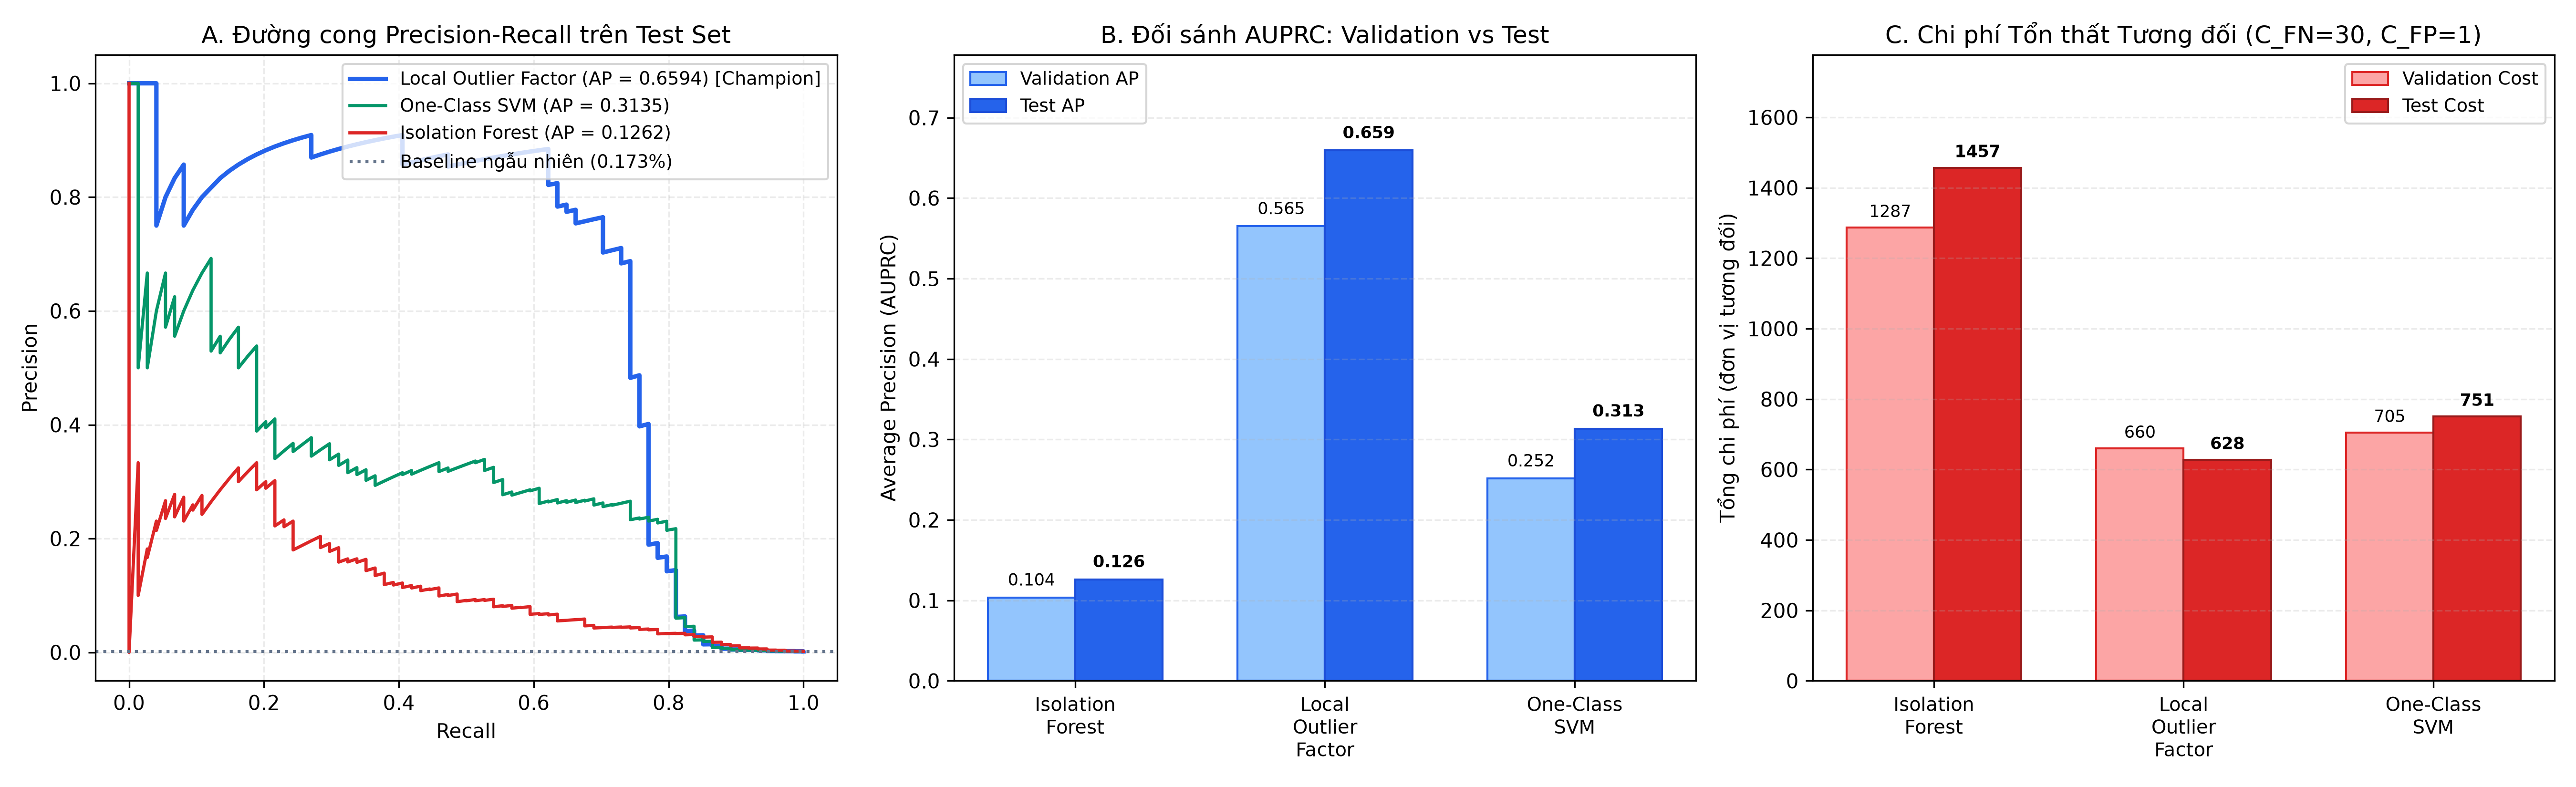

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), facecolor="white")
colors = {"LOF": "#2563EB", "OCSVM": "#059669", "iForest": "#DC2626"}
for tag in ["LOF", "OCSVM", "iForest"]:
    prec, rec, _ = precision_recall_curve(y_test, all_scores[tag])
    row = next(x for x in test_summary if x["model_tag"] == tag)
    axes[0].plot(rec, prec, color=colors[tag], lw=2.2 if tag == "LOF" else 1.6,
                 label=f"{row['model_name']} (AP = {row['test_ap']:.4f}){' [Champion]' if tag=='LOF' else ''}")
axes[0].axhline(n_test_fraud / n_test_samples, color="#64748B", ls=":", label=f"Baseline ngẫu nhiên ({n_test_fraud/n_test_samples*100:.3f}%)")
axes[0].set_title("A. Đường cong Precision-Recall trên Test Set", fontsize=12)
axes[0].set(xlabel="Recall", ylabel="Precision")
axes[0].legend(loc="upper right", fontsize=9)

models_list = [x["model_name"] for x in test_summary]
x_pos, width = np.arange(len(models_list)), 0.35
panels = [
    (axes[1], "B. Đối sánh AUPRC: Validation vs Test", "Average Precision (AUPRC)", "val_ap", "test_ap", ("Validation AP", "Test AP"), ("#93C5FD", "#2563EB"), ("#2563EB", "#1D4ED8"), 0.015, "upper left", False),
    (axes[2], "C. Chi phí Tổn thất Tương đối (C_FN=30, C_FP=1)", "Tổng chi phí (đơn vị tương đối)", "val_cost_ratio30", "test_cost_ratio30", ("Validation Cost", "Test Cost"), ("#FCA5A5", "#DC2626"), ("#DC2626", "#991B1B"), 30, "upper right", True),
]
for ax, title, ylabel, k_val, k_test, lbls, fcols, ecols, pad, leg_loc, use_ylim in panels:
    v_arr, t_arr = [x[k_val] for x in test_summary], [x[k_test] for x in test_summary]
    ax.bar(x_pos - width / 2, v_arr, width, label=lbls[0], color=fcols[0], edgecolor=ecols[0])
    ax.bar(x_pos + width / 2, t_arr, width, label=lbls[1], color=fcols[1], edgecolor=ecols[1])
    ax.set_title(title, fontsize=12)
    ax.set(ylabel=ylabel, xticks=x_pos)
    ax.set_xticklabels([m.replace(" ", "\n") for m in models_list], fontsize=9.5)
    if use_ylim:
        ax.set_ylim(0, max(max(v_arr), max(t_arr)) * 1.22)
    ax.legend(loc=leg_loc, fontsize=9)
    fmt = ".3f" if k_val == "val_ap" else ".0f"
    for i in x_pos:
        ax.text(i - width / 2, v_arr[i] + pad, f"{v_arr[i]:{fmt}}", ha="center", fontsize=8.5)
        ax.text(i + width / 2, t_arr[i] + pad, f"{t_arr[i]:{fmt}}", ha="center", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "17_final_test_evaluation.png", dpi=300)
plt.show()

### Bảng Kết quả Nghiệm thu Đóng băng trên Tập Test (`42,722` mẫu, `74` Fraud — từ `reports/final_test_results.csv` & `final_test_metadata.json`)

| Mô hình | $\tau^*_{\text{Cost}}$ (Đóng băng) | Test AP | Precision | Recall | F1-Score | TP / FP / TN / FN | Test Cost (`30:1`, đơn vị) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Local Outlier Factor (Champion)** | `2.4462849810364786` | **0.659356** | **48.67%** | **74.32%** | **0.5882** | `55 / 58 / 42,590 / 19` | **628** |
| **One-Class SVM** | `1.4075210373883227` | 0.313476 | 23.31% | 74.32% | 0.3548 | `55 / 181 / 42,467 / 19` | 751 |
| **Isolation Forest** | `0.560518556075907` | 0.126228 | 8.39% | 54.05% | 0.1452 | `40 / 437 / 42,211 / 34` | 1,457 |

*(Ngoài ra tại ngưỡng F1-Max đóng băng của LOF $\tau^*_{\text{F1}} = 3.163275669069742$: `TP=47, FP=10, TN=42,638, FN=27`, `Precision=82.46%`, `Recall=63.51%`, `F1=0.7176`, `Cost=820.0` đơn vị.)*

---
## PHẦN E: PHÂN TÍCH LUẬN GIẢI KẾT QUẢ NGHIỆM THU & GIỚI HẠN THỰC TIỄN

### 1. Khả năng Tổng quát hóa Vượt trội (Out-of-sample Generalization):
* **Không hề có Overfitting:** Hiệu năng của mô hình Champion LOF trên Test Set hoàn toàn tương thích và thậm chí còn nhỉnh hơn nhẹ so với Validation Set:
  * Test AP đạt **0.6594** (tăng $+0.0944$ so với Val AP $0.5649$).
  * Tổng chi phí tổn thất tương đối trên Test là **628.0 đơn vị** (thấp hơn Validation là $660.0$ đơn vị; $C_{\text{FN}}=30, C_{\text{FP}}=1$).
  * Bắt đúng **55 / 74 giao dịch gian lận** (Recall = $74.32\%$), chỉ báo nhầm **58** trên tổng số $42,648$ giao dịch bình thường (FP Rate chỉ $0.136\%$).
* **Bảo toàn thứ hạng Champion:** Cả 3 mô hình đều bảo toàn nguyên vẹn thứ hạng sắp xếp từ Validation sang Test:
  $$\text{LOF (AP=0.6594, Cost=628)} \gg \text{OCSVM (AP=0.3135, Cost=751)} \gg \text{iForest (AP=0.1262, Cost=1457)}$$

### 2. Giới hạn Khoa học & Sự khác biệt giữa Nghiên cứu và Thực tiễn Ngân hàng:
1. **Giả định Chi phí Nhân tạo (Synthetic Cost Matrix):** Tỷ lệ $C_{\text{FN}} = 30, C_{\text{FP}} = 1$ là giả định kinh tế hợp lý phục vụ đối sánh học thuật. Trong thực tế ngành tài chính ngân hàng:
   * Chi phí $C_{\text{FN}}$ phụ thuộc trực tiếp vào số tiền gian lận (`Amount`) của giao dịch cụ thể bị bỏ sót, kèm theo chi phí phạt pháp lý, uy tín thương hiệu và phí bồi hoàn Chargeback.
   * Chi phí $C_{\text{FP}}$ phụ thuộc vào trải nghiệm khách hàng (ma sát thanh toán, nguy cơ khách hàng hủy thẻ khi bị từ chối oan liên tục).
2. **Tính Động của Dữ liệu Thực tế (Concept Drift & Zero-day Fraud):** Dữ liệu Kaggle là lát cắt tĩnh trong 2 ngày của năm 2013 tại Châu Âu. Trong môi trường ngân hàng thực chiến, thủ đoạn thay đổi theo thời gian (*Concept Drift*) và $19/74$ ca gian lận bỏ sót (`FN=19`) nằm lẩn sâu trong lõi mật độ Normal, đòi hỏi kết hợp thêm đặc trưng chuỗi thời gian hoặc đồ thị giao dịch.
3. **Nghịch lý ROC-AUC & Benchmark Độ trễ Cục bộ:** Trên Test Set, Isolation Forest đạt `ROC-AUC = 0.9450` (cao hơn LOF `0.9310`) nhưng `Test AP = 0.1262` do phát sinh `437` báo nhầm (`FPR ~ 1.02%` nhưng Precision chỉ `8.39%`). Về tốc độ tính điểm vector cục bộ cho LOF: Phase 4 lô 5,000 mẫu đạt `~0.2166 ms/tx`, Phase 6 Validation đạt `0.0817 ms/tx`, và Phase 8 Test đạt `0.0175 ms/tx` (Cell 8, `0.746s`) / `0.0179 ms/tx` (Cell 10); đây chỉ là benchmark phần cứng cục bộ, không phải cam kết SLA cổng thanh toán thực tế.
4. **Độ nhạy Chi phí & Kỷ luật Thử nghiệm:** Tại Phase 6 Validation, LOF thắng chi phí ở `10:1` (`256.0`), `20:1` (`460.0`) và tỷ lệ chính `30:1` (`660.0`), trong khi One-Class SVM thấp hơn ở `50:1` (`1037.0` vs `1060.0`) và `100:1` (`1837.0` vs `2020.0`) nhờ Recall cao hơn (`0.7703`). Ngưỡng `float64` $\tau^* = 2.4462849810364786$ được giữ nguyên không làm tròn để bảo toàn tái lập bit-for-bit.